<a href="https://colab.research.google.com/github/Sinrez/PythonProjects/blob/main/hw10_end.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.style.use('ggplot')

1. Анализ погоды

Исходные данные:
         data    city  temperature
0  2026-01-01  Москва         -5.0
1  2026-01-02  Москва         -3.0
2  2026-01-03  Москва          NaN
3  2026-01-01  Казань         -8.0
4  2026-01-02  Казань         -6.0
5  2026-01-03  Казань         -4.0

После удаления NaN:
         data    city  temperature
0  2026-01-01  Москва         -5.0
1  2026-01-02  Москва         -3.0
3  2026-01-01  Казань         -8.0
4  2026-01-02  Казань         -6.0
5  2026-01-03  Казань         -4.0

Типы данных после конвертации:
data           datetime64[ns]
city                   object
temperature           float64
dtype: object

Средняя температура по городам и датам:
     city       data  temperature
0  Казань 2026-01-01         -8.0
1  Казань 2026-01-02         -6.0
2  Казань 2026-01-03         -4.0
3  Москва 2026-01-01         -5.0
4  Москва 2026-01-02         -3.0


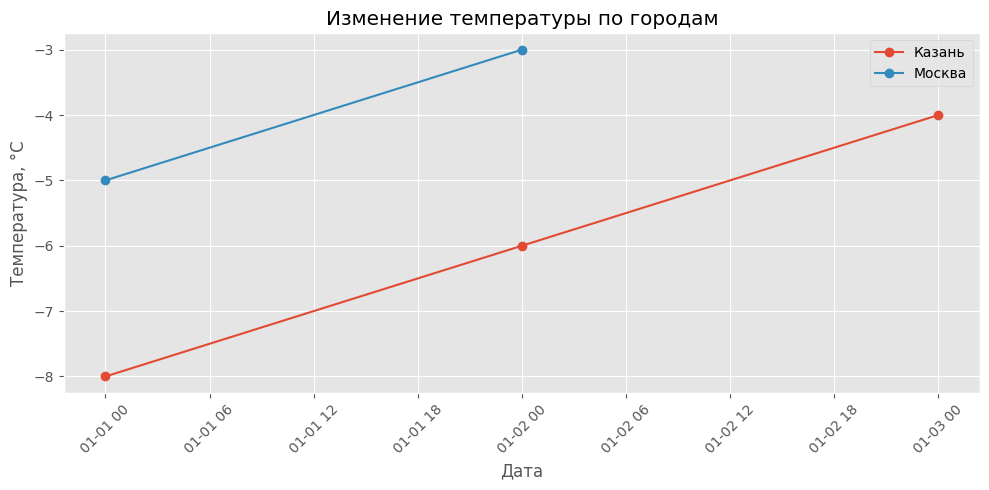

In [2]:
weather = pd.read_csv('weather.csv')
print("Исходные данные:")
print(weather)

# Удаление записей с отсутствующей температурой
weather = weather.dropna(subset=['temperature'])
print("\nПосле удаления NaN:")
print(weather)

weather['data'] = pd.to_datetime(weather['data'])
print("\nТипы данных после конвертации:")
print(weather.dtypes)

weather_grouped = weather.groupby(['city', 'data'])['temperature'].mean().reset_index()
print("\nСредняя температура по городам и датам:")
print(weather_grouped)

plt.figure(figsize=(10, 5))
for city in weather_grouped['city'].unique():
    city_data = weather_grouped[weather_grouped['city'] == city]
    plt.plot(city_data['data'], city_data['temperature'], marker='o', label=city)

plt.title('Изменение температуры по городам')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

2. Анализ успеваемости студентов

Исходные данные:
   student group subject  grade
0     Иван     А  Python      5
1     Анна     А  Python      4
2     Пётр     Б  Python      3
3    Мария     Б  Python      5
4  Алексей     А  Python      2
5    Ольга     Б  Python      4

После удаления пропущенных оценок:
   student group subject  grade
0     Иван     А  Python      5
1     Анна     А  Python      4
2     Пётр     Б  Python      3
3    Мария     Б  Python      5
4  Алексей     А  Python      2
5    Ольга     Б  Python      4

Студенты с оценкой 3 и выше:
  student group subject  grade
0    Иван     А  Python      5
1    Анна     А  Python      4
2    Пётр     Б  Python      3
3   Мария     Б  Python      5
5   Ольга     Б  Python      4

Средний балл по группам:
  group  average_grade
0     А            4.5
1     Б            4.0


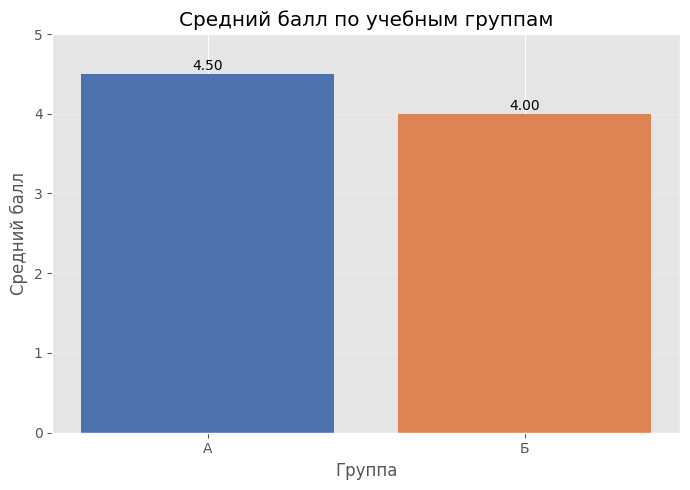

In [3]:
students = pd.read_csv('students.csv')
print("Исходные данные:")
print(students)

#зачистки
students = students.dropna(subset=['grade'])
print("\nПосле удаления пропущенных оценок:")
print(students)

# Фильтрация студентов с оценкой 3 или выше
students_filtered = students[students['grade'] >= 3]
print("\nСтуденты с оценкой 3 и выше:")
print(students_filtered)

group_avg = students_filtered.groupby('group')['grade'].mean().reset_index()
group_avg.columns = ['group', 'average_grade']
print("\nСредний балл по группам:")
print(group_avg)

plt.figure(figsize=(7, 5))
plt.bar(group_avg['group'], group_avg['average_grade'], color=['#4C72B0', '#DD8452'])
plt.title('Средний балл по учебным группам')
plt.xlabel('Группа')
plt.ylabel('Средний балл')
plt.ylim(0, 5)
for i, v in enumerate(group_avg['average_grade']):
    plt.text(i, v + 0.05, f'{v:.2f}', ha='center')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Анализ продаж инет-магазина

Исходные данные:
    product     category  quantity  price
0    Laptop  Electronics         2  85000
1     Mouse  Accessories         5   1500
2  Keyboard  Accessories         3   4000
3   Monitor  Electronics         2  25000
4    Laptop  Electronics         1  85000
5     Mouse  Accessories         4   1500

После удаления пропусков:
    product     category  quantity  price
0    Laptop  Electronics         2  85000
1     Mouse  Accessories         5   1500
2  Keyboard  Accessories         3   4000
3   Monitor  Electronics         2  25000
4    Laptop  Electronics         1  85000
5     Mouse  Accessories         4   1500

Данные с выручкой:
    product     category  quantity  price  revenue
0    Laptop  Electronics         2  85000   170000
1     Mouse  Accessories         5   1500     7500
2  Keyboard  Accessories         3   4000    12000
3   Monitor  Electronics         2  25000    50000
4    Laptop  Electronics         1  85000    85000
5     Mouse  Accessories         4   1500 

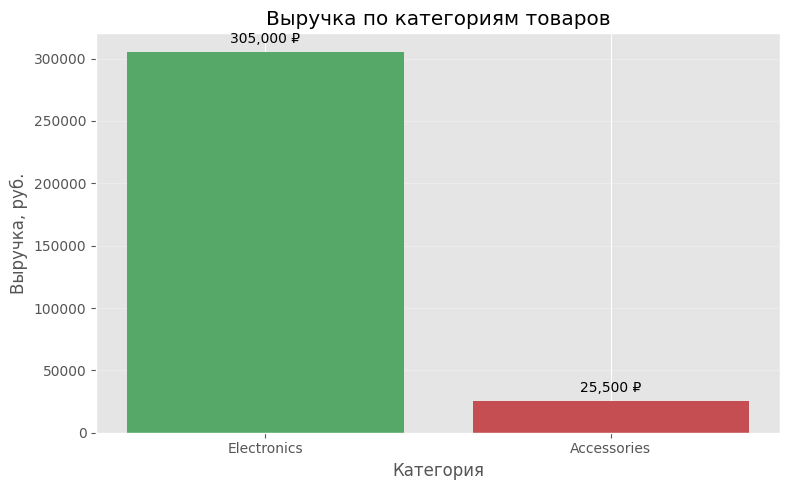

In [4]:
sales = pd.read_csv('sales.csv')
print("Исходные данные:")
print(sales)

sales = sales.dropna()
print("\nПосле удаления пропусков:")
print(sales)

# revenue (выручка = quantity * price)
sales['revenue'] = sales['quantity'] * sales['price']
print("\nДанные с выручкой:")
print(sales)

# Группировка по категориям и расчёт общей выручки
category_revenue = sales.groupby('category')['revenue'].sum().reset_index()
category_revenue = category_revenue.sort_values('revenue', ascending=False)
print("\nОбщая выручка по категориям:")
print(category_revenue)

plt.figure(figsize=(8, 5))
bars = plt.bar(category_revenue['category'], category_revenue['revenue'], color=['#55A868', '#C44E52'])
plt.title('Выручка по категориям товаров')
plt.xlabel('Категория')
plt.ylabel('Выручка, руб.')
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 5000,
             f'{height:,.0f} ₽', ha='center', va='bottom', fontsize=10)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()